In [1]:
# Gerekli kütüphanelerin yüklenmesi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

df = pd.read_csv('heart.csv')

print("Veri Setinin İlk Hali:")
display(df.head())

Veri Setinin İlk Hali:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
#1. ADIM: ÖN HAZIRLIK (Eksik verilerin tanımlanması)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)


# 2. ADIM: DURUM ANALİZİ (Doluluk oranına bakma)
print("\n--- Doldurma İşlemi Öncesi Veri Seti Durumu ---")
doluluk_oranlari = df.count() / len(df) * 100

doluluk_tablosu = pd.DataFrame({
    'Toplam Veri': len(df),
    'Dolu Veri': df.count(),
    'Eksik Veri': df.isna().sum(),
    'Doluluk Oranı (%)': doluluk_oranlari
})

print(doluluk_tablosu.sort_values(by='Doluluk Oranı (%)', ascending=False))
print("-" * 40)


# 3. ADIM: EKSİK VERİLERİ DOLDURMA (Ortalama ile atama)

cholesterol_mean = df['Cholesterol'].mean()

df['Cholesterol'] = df['Cholesterol'].fillna(cholesterol_mean)

print(f"\nİşlem Tamamlandı: Cholesterol sütunundaki eksik veriler ortalama ({cholesterol_mean:.2f}) ile dolduruldu.")


--- Doldurma İşlemi Öncesi Veri Seti Durumu ---
                Toplam Veri  Dolu Veri  Eksik Veri  Doluluk Oranı (%)
Age                     918        918           0         100.000000
Sex                     918        918           0         100.000000
ChestPainType           918        918           0         100.000000
RestingBP               918        918           0         100.000000
FastingBS               918        918           0         100.000000
RestingECG              918        918           0         100.000000
MaxHR                   918        918           0         100.000000
ExerciseAngina          918        918           0         100.000000
ST_Slope                918        918           0         100.000000
Oldpeak                 918        918           0         100.000000
HeartDisease            918        918           0         100.000000
Cholesterol             918        746         172          81.263617
----------------------------------------


In [3]:
# --- ADIM 2: GÜRÜLTÜLÜ VERİ VE AYKIRI DEĞER TEMİZLİĞİ ---
#  Z-Score hesaplanır
numerical_cols = ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'Age']
z_scores = np.abs(stats.zscore(df[numerical_cols]))

outlier_indices = (z_scores > 3).any(axis=1)

print(f"\nToplam Aykırı Değer Sayısı (Z-Score > 3): {outlier_indices.sum()}")

df_cleaned = df[~outlier_indices].copy()
print(f"Aykırı değerler temizlendikten sonraki satır sayısı: {df_cleaned.shape[0]}")


Toplam Aykırı Değer Sayısı (Z-Score > 3): 28
Aykırı değerler temizlendikten sonraki satır sayısı: 890


In [4]:
# --- ADIM 3: KATEGORİK VERİ DÖNÜŞÜMÜ (ENCODING) ---
le = LabelEncoder()
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in categorical_cols:
    df_cleaned[col] = le.fit_transform(df_cleaned[col])

print("Kategorik veriler sayısala dönüştürüldü (Label Encoding).")
display(df_cleaned[categorical_cols].head())

Kategorik veriler sayısala dönüştürüldü (Label Encoding).


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,1,1,1,0,2
1,0,2,1,0,1
2,1,1,2,0,2
3,0,0,1,1,1
4,1,2,1,0,2


In [5]:
# --- ADIM 4: NORMALİZASYON ---
scaler = MinMaxScaler()
cols_to_scale = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
df_cleaned[cols_to_scale] = scaler.fit_transform(df_cleaned[cols_to_scale])

print("\nMin-Max Normalizasyonu Sonrası Veri (İlk 5 Satır):")
display(df_cleaned.head())


Min-Max Normalizasyonu Sonrası Veri (İlk 5 Satır):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0.244898,1,1,0.571429,0.639498,0,1,0.784173,0,0.333333,2,0
1,0.428571,0,2,0.761905,0.297806,0,1,0.669065,0,0.500000,1,1
2,0.183673,1,1,0.476190,0.620690,0,2,0.251799,0,0.333333,2,0
3,0.408163,0,0,0.552381,0.404389,0,1,0.323741,1,0.583333,1,1
4,0.530612,1,2,0.666667,0.344828,0,1,0.424460,0,0.333333,2,0


In [6]:
# --- ADIM 5: NİTELİK OLUŞTURMA (FEATURE ENGINEERING) ---
bins = [0, 40, 60, 100]
labels = [0, 1, 2] # 0: Genç, 1: Orta, 2: Yaşlı

original_ages = df.loc[df_cleaned.index, 'Age']
df_cleaned['Age_Category'] = pd.cut(original_ages, bins=bins, labels=labels)

df_cleaned['Age_Category'] = df_cleaned['Age_Category'].astype(int)

print("Yaş kategorileri oluşturuldu.")
display(df_cleaned[['Age', 'Age_Category']].head())

Yaş kategorileri oluşturuldu.


,Age,Age_Category
0,0.244898,0
1,0.428571,1
2,0.183673,0
3,0.408163,1
4,0.530612,1


In [7]:
print("\nÖnişleme Tamamlandı. Veri Seti Özeti:")
print(df_cleaned.info())

X = df_cleaned.drop('HeartDisease', axis=1)
y = df_cleaned['HeartDisease']

df_cleaned.to_csv('heart_onislenmis.csv', index=False)

print("Dosya başarıyla kaydedildi: heart_onislenmis.csv")


Önişleme Tamamlandı. Veri Seti Özeti:
<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 0 to 917
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             890 non-null    float64
 1   Sex             890 non-null    int64  
 2   ChestPainType   890 non-null    int64  
 3   RestingBP       890 non-null    float64
 4   Cholesterol     890 non-null    float64
 5   FastingBS       890 non-null    int64  
 6   RestingECG      890 non-null    int64  
 7   MaxHR           890 non-null    float64
 8   ExerciseAngina  890 non-null    int64  
 9   Oldpeak         890 non-null    float64
 10  ST_Slope        890 non-null    int64  
 11  HeartDisease    890 non-null    int64  
 12  Age_Category    890 non-null    int64  
dtypes: float64(5), int64(8)
memory usage: 97.3 KB
None
Dosya başarıyla kaydedildi: heart_onislenmis.csv


In [8]:
# Gerekli kütüphanelerin eklenmesi
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# --- ADIM 1: Veriyi X (Özellikler) ve y (Hedef) olarak ayırma
X = df_cleaned.drop('HeartDisease', axis=1)
y = df_cleaned['HeartDisease']

In [9]:
# --- ADIM 2: AYIRMA İŞLEMİ ---

# 1. Parçalama: Veriyi %90 (İşlenecek Kısım) ve %10 (Kenara Ayrılan/Holdout) olarak bölüyoruz.
X_temp, X_holdout, y_temp, y_holdout = train_test_split(X, y, test_size=0.10, random_state=42)

print(f"Toplam Veri Sayısı: {len(X)}")
print(f"Kenara Ayrılan (%10) Veri Sayısı: {len(X_holdout)}")
print(f"Eğitim/Test İçin Kullanılacak (%90) Veri Sayısı: {len(X_temp)}")

# 2. Parçalama: O %90'lık kısmı (X_temp), kendi içinde %80 Eğitim ve %20 Test olarak bölüyoruz.
X_train, X_test, y_train, y_test = train_test_split(X_temp, y_temp, test_size=0.20, random_state=42)

print(f"Model Eğitimi İçin Kullanılacak Veri (X_train): {len(X_train)}")
print(f"Model Testi İçin Kullanılacak Veri (X_test): {len(X_test)}")

Toplam Veri Sayısı: 890
Kenara Ayrılan (%10) Veri Sayısı: 89
Eğitim/Test İçin Kullanılacak (%90) Veri Sayısı: 801
Model Eğitimi İçin Kullanılacak Veri (X_train): 640
Model Testi İçin Kullanılacak Veri (X_test): 161


In [10]:
# --- ADIM 3: RANDOM FOREST MODELİ VE CROSS VALIDATION ---

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Cross Validation 
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5)

print("\n--- Cross Validation (Çapraz Doğrulama) Sonuçları ---")
print(f"Skorlar: {cv_scores}")
print(f"Ortalama Doğruluk (Accuracy): {cv_scores.mean():.4f}")


--- Cross Validation (Çapraz Doğrulama) Sonuçları ---
Skorlar: [0.8828125 0.8046875 0.875     0.875     0.890625 ]
Ortalama Doğruluk (Accuracy): 0.8656



--- Test Seti Sonuçları ---
Test Seti Doğruluk Oranı (Accuracy): 0.8385

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        71
           1       0.85      0.87      0.86        90

    accuracy                           0.84       161
   macro avg       0.84      0.83      0.84       161
weighted avg       0.84      0.84      0.84       161



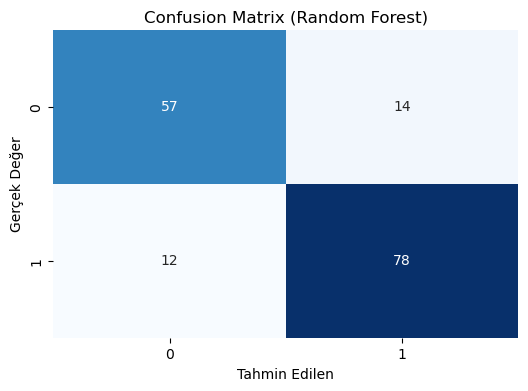

In [11]:
# --- ADIM 4: MODELİN EĞİTİLMESİ VE TEST EDİLMESİ ---

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

# --- ADIM 5: SONUÇLARIN RAPORLANMASI  ---
print("\n--- Test Seti Sonuçları ---")
acc = accuracy_score(y_test, y_pred)
print(f"Test Seti Doğruluk Oranı (Accuracy): {acc:.4f}")

print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

# Karışıklık Matrisi (Confusion Matrix) Görselleştirme
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('Confusion Matrix (Random Forest)')
plt.show()

In [12]:
# --- ADIM 6: HOLDOUT (KENARA AYRILAN) VERİ İLE FİNAL TESTİ ---
print("\n--- Holdout (Kenara Ayrılan %10) Seti Sonuçları ---")
# Eğitilmiş model ile holdout setini tahmin et
y_holdout_pred = rf_model.predict(X_holdout)

acc_holdout = accuracy_score(y_holdout, y_holdout_pred)
print(f"Holdout Seti Doğruluk Oranı: {acc_holdout:.4f}")

print(classification_report(y_holdout, y_holdout_pred))


--- Holdout (Kenara Ayrılan %10) Seti Sonuçları ---
Holdout Seti Doğruluk Oranı: 0.9438
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        40
           1       0.96      0.94      0.95        49

    accuracy                           0.94        89
   macro avg       0.94      0.94      0.94        89
weighted avg       0.94      0.94      0.94        89



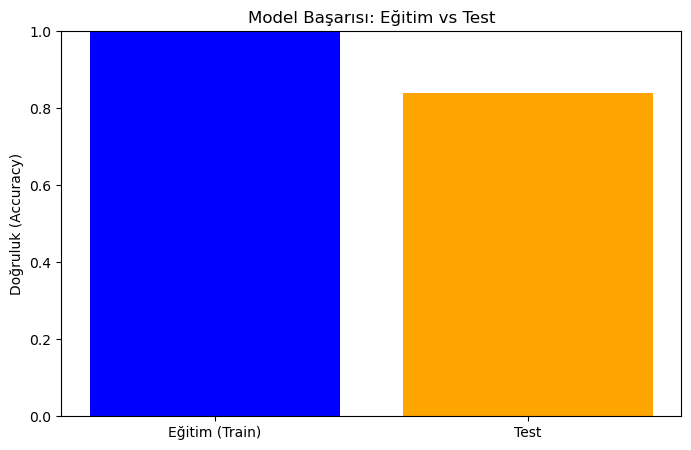

In [13]:
# Eğitim başarısı
train_acc = accuracy_score(y_train, rf_model.predict(X_train))
# Test başarısı (zaten hesaplamıştın: acc)

plt.figure(figsize=(8, 5))
plt.bar(['Eğitim (Train)', 'Test'], [train_acc, acc], color=['blue', 'orange'])
plt.ylim(0, 1)
plt.title('Model Başarısı: Eğitim vs Test')
plt.ylabel('Doğruluk (Accuracy)')
plt.show()

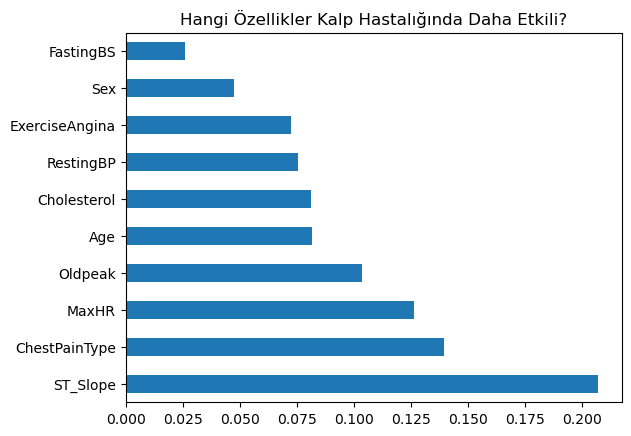

In [14]:
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh')
plt.title("Hangi Özellikler Kalp Hastalığında Daha Etkili?")
plt.show()

In [1]:
# -----------------------------------------------------------------------------
# ADIM 1: GEREKLİ KÜTÜPHANELERİN VE AYARLARIN YÜKLENMESİ
# -----------------------------------------------------------------------------
import warnings
warnings.filterwarnings('ignore')


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

veri = pd.read_csv("heart_onislenmis.csv")
X = veri.drop('HeartDisease', axis=1)
y = veri['HeartDisease']

In [2]:
# -----------------------------------------------------------------------------
# ADIM 2: VERİ YÜKLEME VE PARÇALAMA (ÇİFT AŞAMALI BÖLME)
# -----------------------------------------------------------------------------

X_gecici, X_sakli, y_gecici, y_sakli = train_test_split(X, y, test_size=0.10, random_state=42)

X_egitim, X_test, y_egitim, y_test = train_test_split(X_gecici, y_gecici, test_size=0.20, random_state=42)

print(f"Eğitim Verisi Sayısı: {len(X_egitim)}")
print(f"Test Verisi Sayısı: {len(X_test)}")

Eğitim Verisi Sayısı: 640
Test Verisi Sayısı: 161


In [3]:
# -----------------------------------------------------------------------------
# ADIM 3: MODEL KURULUMU VE ÇAPRAZ DOĞRULAMA
# -----------------------------------------------------------------------------

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

capraz_dogrulama_skorlari = cross_val_score(model, X_egitim, y_egitim, cv=5)

print("\n--- Çapraz Doğrulama (Cross Validation) Sonuçları ---")
temiz_skorlar = [f"{puan:.2f}" for puan in capraz_dogrulama_skorlari]
print(f"5 Farklı Deneme Sonucu: {', '.join(temiz_skorlar)}") 
print(f"Ortalama Başarı Puanı:  {capraz_dogrulama_skorlari.mean():.2f}")


--- Çapraz Doğrulama (Cross Validation) Sonuçları ---
5 Farklı Deneme Sonucu: 0.88, 0.84, 0.90, 0.88, 0.85
Ortalama Başarı Puanı:  0.87


In [4]:
# -----------------------------------------------------------------------------
# ADIM 4: EĞİTİM VE TEST
# -----------------------------------------------------------------------------

model.fit(X_egitim, y_egitim)
y_tahmin = model.predict(X_test)

dogruluk_orani = accuracy_score(y_test, y_tahmin)
print(f"\nModelin Test Seti Doğruluğu: {dogruluk_orani:.2f}")

print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_tahmin))


Modelin Test Seti Doğruluğu: 0.84

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        71
           1       0.85      0.87      0.86        90

    accuracy                           0.84       161
   macro avg       0.84      0.83      0.84       161
weighted avg       0.84      0.84      0.84       161



In [5]:
# -----------------------------------------------------------------------------
# ADIM 5: KAYDETME
# -----------------------------------------------------------------------------
joblib.dump(model, "kalp_modeli_gb.pkl")
print("\nModel başarıyla 'kalp_modeli_gb.pkl' dosyasına kaydedildi.")


Model başarıyla 'kalp_modeli_gb.pkl' dosyasına kaydedildi.


In [6]:
# -----------------------------------------------------------------------------
# ADIM 6: GERİ YÜKLEME VE SAKLI VERİ (FİNAL) TESTİ
# -----------------------------------------------------------------------------

yuklenen_model = joblib.load("kalp_modeli_gb.pkl")
yeni_tahminler = yuklenen_model.predict(X_sakli)

sonuc_tablosu = X_sakli.copy()
sonuc_tablosu["Gercek_Durum"] = y_sakli
sonuc_tablosu["Modelin_Tahmini"] = yeni_tahminler

print("\nSaklı Veri (Holdout) Üzerindeki Tahminler (İlk 5 Satır):")
display(sonuc_tablosu.head())

final_basarisi = accuracy_score(y_sakli, yeni_tahminler)
print(f"\n>>> SAKLI VERİ (FİNAL) DOĞRULUK ORANI: {final_basarisi:.2f} <<<")

sonuc_tablosu.to_csv("tahmin_sonuclari.csv", index=False)
print("Tahmin sonuçları kaydedildi.")


Saklı Veri (Holdout) Üzerindeki Tahminler (İlk 5 Satır):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Age_Category,Gercek_Durum,Modelin_Tahmini
280,0.408163,1,2,0.285714,0.394984,0,1,0.539568,0,0.333333,2,1,0,0
434,0.714286,1,0,0.761905,0.454545,1,1,0.302158,1,0.500000,1,2,1,1
39,0.530612,0,2,0.476190,0.655172,0,2,0.266187,1,0.333333,1,1,1,0
417,0.693878,1,0,0.380952,0.423197,0,2,0.165468,0,0.333333,2,2,0,0
585,0.673469,1,2,0.380952,0.789969,0,1,0.251799,1,0.333333,1,2,1,1



>>> SAKLI VERİ (FİNAL) DOĞRULUK ORANI: 0.91 <<<
Tahmin sonuçları kaydedildi.


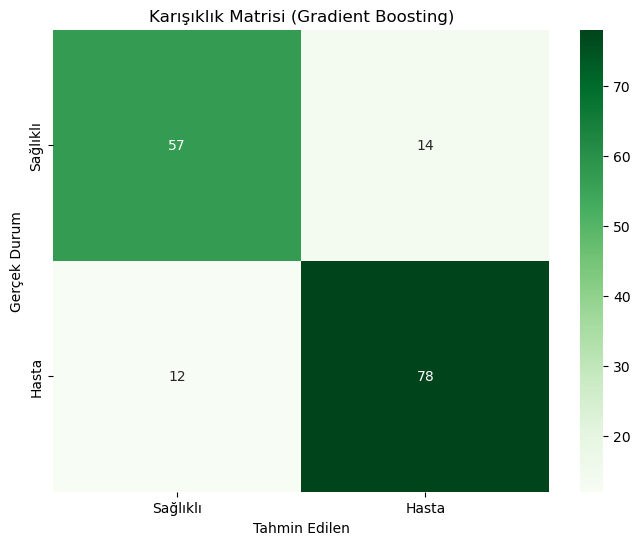

In [7]:
# -----------------------------------------------------------------------------
# ADIM 7: CONFUSION MATRIX
# -----------------------------------------------------------------------------
karmasiklik_matrisi = confusion_matrix(y_test, y_tahmin)
plt.figure(figsize=(8, 6))
sns.heatmap(karmasiklik_matrisi, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Sağlıklı", "Hasta"], yticklabels=["Sağlıklı", "Hasta"])
plt.title("Karışıklık Matrisi (Gradient Boosting)")
plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek Durum")
plt.show()

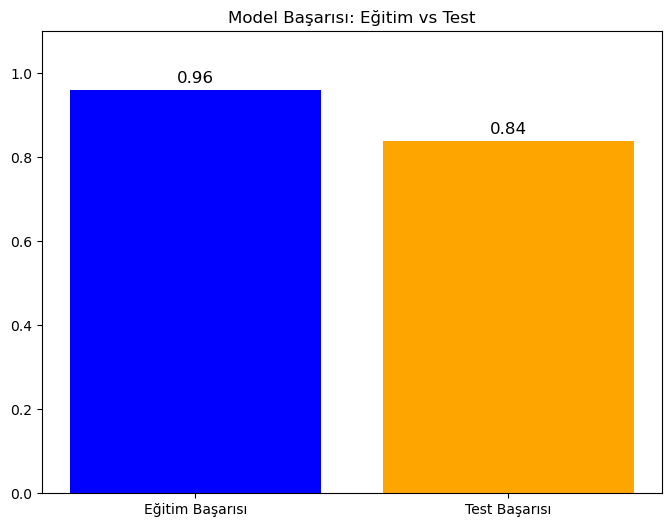

In [8]:
# -----------------------------------------------------------------------------
# ADIM 8: EĞİTİM vs TEST GRAFİĞİ
# -----------------------------------------------------------------------------
egitim_basarisi = accuracy_score(y_egitim, model.predict(X_egitim))
test_basarisi = accuracy_score(y_test, y_tahmin)

plt.figure(figsize=(8, 6))
cubuklar = plt.bar(["Eğitim Başarısı", "Test Başarısı"], 
               [egitim_basarisi, test_basarisi], color=['blue', 'orange'])
for cubuk in cubuklar:
    plt.text(cubuk.get_x() + cubuk.get_width()/2, cubuk.get_height() + 0.01, 
             round(cubuk.get_height(), 2), ha='center', va='bottom', fontsize=12)
plt.ylim(0, 1.1)
plt.title("Model Başarısı: Eğitim vs Test")
plt.show()

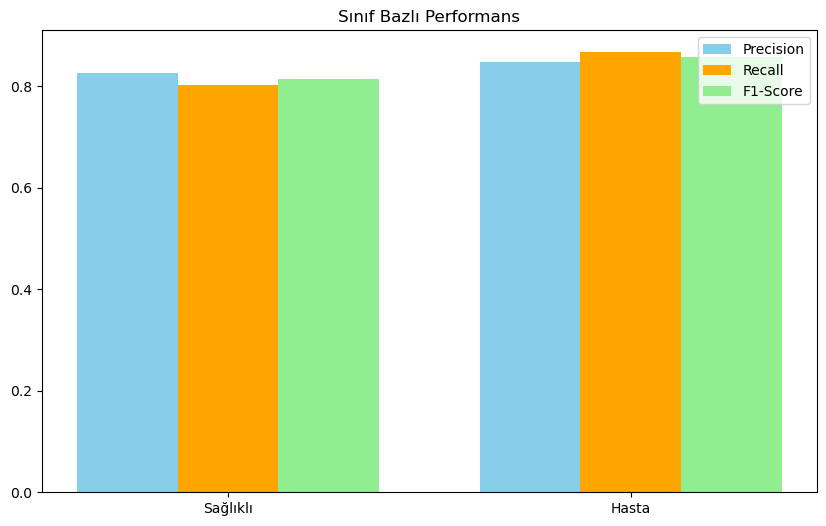

In [9]:
# -----------------------------------------------------------------------------
# ADIM 9: DETAYLI METRİKLER GRAFİĞİ
# -----------------------------------------------------------------------------
rapor = classification_report(y_test, y_tahmin, output_dict=True)
siniflar = [str(c) for c in list(rapor.keys())[:-3]]
kesinlik = [rapor[c]["precision"] for c in siniflar]
duyarlilik = [rapor[c]["recall"] for c in siniflar]
f1 = [rapor[c]["f1-score"] for c in siniflar]

x = np.arange(len(siniflar))
plt.figure(figsize=(10, 6))
plt.bar(x - 0.25, kesinlik, 0.25, label="Precision", color='skyblue')
plt.bar(x, duyarlilik, 0.25, label="Recall", color='orange')
plt.bar(x + 0.25, f1, 0.25, label="F1-Score", color='lightgreen')
plt.xticks(x, ["Sağlıklı", "Hasta"])
plt.legend()
plt.title("Sınıf Bazlı Performans")
plt.show()

In [10]:
# ---------------------------------------------------------
# KÜTÜPHANE İMPORTLARI (Hoca Sorarsa: "Bu kütüphaneler bu işin standardıdır.")
# ---------------------------------------------------------

# [AÇIKLAMA]: Pandas, veriyi Excel tablosu gibi (satır/sütun) bellekte tutmamızı sağlar.
import pandas as pd

# [AÇIKLAMA]: Numpy, matematiksel işlemler ve matrisler için gereklidir.
import numpy as np

# [AÇIKLAMA]: Matplotlib, sonuçları grafiğe dökmek ve ağ yapısını çizdirmek için kullanılır.
import matplotlib.pyplot as plt

# [AÇIKLAMA]: NetworkX, çizge teorisi (Graph Theory) kütüphanesidir.
# [NEDEN?]: Bayesian ağındaki düğümleri (node) ve okları (edge) hesaplamak ve çizmek için buna ihtiyacımız var.
import networkx as nx

# [AÇIKLAMA]: Kod çalışırken versiyon uyuşmazlığı gibi önemsiz uyarıların ekrana basılmasını engeller.
import warnings

# --- SKLEARN KÜTÜPHANESİ ---
# [AÇIKLAMA]: Veriyi eğitim ve test olarak bölmek için kullanılan standart fonksiyondur.
from sklearn.model_selection import train_test_split

# [AÇIKLAMA]: Modelin başarısını ölçen metrikler.
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# --- PGMPY KÜTÜPHANESİ (PROBABILISTIC GRAPHICAL MODELS) ---
# [HOCA SORARSA]: "Neden pgmpy?" -> "Python'da Bayesian Ağları kurmak için en gelişmiş ve akademik kütüphane budur."

try:
    # En yeni versiyonlarda isim 'DiscreteBayesianNetwork' oldu.
    # [NEDEN DISCRETE?]: Çünkü Bayesian ağları kategorik verilerle (Var/Yok, Düşük/Yüksek) çalışır.
    from pgmpy.models import DiscreteBayesianNetwork as BN_Model
except ImportError:
    try:
        from pgmpy.models import BayesianNetwork as BN_Model
    except ImportError:
        # Eski versiyonlarda adı BayesianModel idi.
        from pgmpy.models import BayesianModel as BN_Model

# [AÇIKLAMA]: TreeSearch -> Verideki ilişkileri tarayıp en iyi ağaç yapısını bulan algoritma.
# [AÇIKLAMA]: MaximumLikelihoodEstimator -> Verideki olayları sayarak olasılık tablosunu (CPT) dolduran hesaplayıcı.
from pgmpy.estimators import TreeSearch, MaximumLikelihoodEstimator

# [AÇIKLAMA]: Modelin veriye istatistiksel olarak ne kadar iyi uyduğunu ölçen puan.
from pgmpy.metrics import log_likelihood_score

# [AÇIKLAMA]: Gereksiz kırmızı uyarı yazılarını gizle.
warnings.filterwarnings('ignore')

print("Sistem ve Kütüphaneler Başlatıldı.")

Sistem ve Kütüphaneler Başlatıldı.


In [11]:
# ---------------------------------------------------------
# ADIM 1: VERİ YÜKLEME VE HAZIRLIK
# ---------------------------------------------------------
print("\n--- 1. VERİ YÜKLENİYOR ---")

# [AÇIKLAMA]: İşlenecek dosyanın adı.
csv_file_name = 'heart_onislenmis.csv'
# [AÇIKLAMA]: Tahmin etmeye çalıştığımız ana sütun (Kalp Hastalığı: 1 veya 0).
target_col = 'HeartDisease'

try:
    # [AÇIKLAMA]: CSV dosyasını okuyup 'df' (DataFrame) değişkenine atıyoruz.
    df = pd.read_csv(csv_file_name)
    print(f"Dosya '{csv_file_name}' başarıyla yüklendi.")
except FileNotFoundError:
    print(f"HATA: '{csv_file_name}' bulunamadı! Dosya yolunu kontrol edin.")
    raise

# [AÇIKLAMA]: X -> Girdi verileri, y -> Çıktı verisi.
X = df.drop(target_col, axis=1) 
y = df[target_col]

# [AÇIKLAMA]: Veriyi bölüyoruz (%80 Eğitim, %20 Test).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# [AÇIKLAMA]: Pgmpy kütüphanesinin çalışma mantığı Scikit-learn'den farklıdır.
# Pgmpy eğitim için X ve y'yi tek bir tablo (DataFrame) içinde ister.
train_data = pd.concat([X_train, y_train], axis=1).reset_index(drop=True)

# [AÇIKLAMA]: Test verilerini de aynı şekilde hazırlıyoruz.
test_data_features = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)

# [AÇIKLAMA]: Bu 'test_data_full', hocanın istediği ekstra döngüde kullanılacak.
test_data_full = pd.concat([test_data_features, y_test_reset], axis=1)
print("Veri setleri Pgmpy formatına uygun hale getirildi.")


--- 1. VERİ YÜKLENİYOR ---
Dosya 'heart_onislenmis.csv' başarıyla yüklendi.
Veri setleri Pgmpy formatına uygun hale getirildi.


In [12]:
# ---------------------------------------------------------
# ADIM 2: KATEGORİKLEŞTİRME (DISCRETIZATION)
# ---------------------------------------------------------
print("Veriler kategorik hale getiriliyor (Discretization)...")

# [AÇIKLAMA]: Sayısal (continuous) olan sütunların listesi.
continuous_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

for col in continuous_cols:
    # Eğer bu sütun verimizde varsa işlem yap:
    if col in train_data.columns:
        # [AÇIKLAMA]: pd.cut fonksiyonu veriyi dilimler (bins=5).
        train_data[col] = pd.cut(train_data[col], bins=5, labels=False)
        # Aynı dönüşümü test verisine de uygulamak zorundayız.
        test_data_full[col] = pd.cut(test_data_full[col], bins=5, labels=False)

# [AÇIKLAMA]: Pgmpy verilerin "string" (metin) tipinde olmasını sever.
train_data = train_data.astype(str)
test_data_full = test_data_full.astype(str)

print("Sayısal veriler kategorilere (bins) ayrıldı.")
display(train_data.head())

Veriler kategorik hale getiriliyor (Discretization)...
Sayısal veriler kategorilere (bins) ayrıldı.


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Age_Category,HeartDisease
0,1,1,1,1,3,0,1,3,0,1,2,1,0
1,1,1,0,2,2,0,2,2,1,2,1,1,1
2,2,1,0,3,2,1,1,1,1,3,1,1,1
3,2,1,0,2,3,0,1,4,1,2,2,1,1
4,1,0,2,0,1,0,1,4,0,1,2,0,0


In [13]:
# ---------------------------------------------------------
# ADIM 3: YAPISAL ÖĞRENME (TAN MODELİ)
# ---------------------------------------------------------
print("\n--- 2. MODEL YAPISI ÖĞRENİLİYOR (TAN) ---")

dag = None # DAG: Directed Acyclic Graph - Ağın iskeleti.

try:
    # [AÇIKLAMA]: TreeSearch ile ağaç yapısını araştırıyoruz.
    est = TreeSearch(train_data)
    
    # [AÇIKLAMA]: estimator_type='tan' ve class_node=target_col
    # Ağacın kökünü 'HeartDisease' yapıyoruz.
    dag = est.estimate(estimator_type='tan', class_node=target_col)
    print("Yapı öğrenildi (Yöntem: class_node).")
except Exception:
    # Yedek yöntemler (versiyon farkı için)
    try:
        est = TreeSearch(train_data, root_node=target_col)
        dag = est.estimate(estimator_type='tan')
        print("Yapı öğrenildi (Yöntem: root_node init).")
    except Exception:
        est = TreeSearch(train_data)
        dag = est.estimate(estimator_type='tan', root_node=target_col)
        print("Yapı öğrenildi (Yöntem: root_node estimate).")

print(f"Toplam Bağlantı Sayısı: {len(dag.edges())}")

# [AÇIKLAMA]: Modeli oluştur ve olasılıkları (CPT) hesapla.
model = BN_Model(dag.edges())
model.fit(train_data, estimator=MaximumLikelihoodEstimator)
print("Model eğitildi ve olasılık tabloları hesaplandı.")

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'C', 'Sex': 'C', 'ChestPainType': 'C', 'RestingBP': 'C', 'Cholesterol': 'C', 'FastingBS': 'C', 'RestingECG': 'C', 'MaxHR': 'C', 'ExerciseAngina': 'C', 'Oldpeak': 'C', 'ST_Slope': 'C', 'Age_Category': 'C', 'HeartDisease': 'C'}



--- 2. MODEL YAPISI ÖĞRENİLİYOR (TAN) ---


Building tree:   0%|          | 0/78.0 [00:00<?, ?it/s]

Building tree:   0%|          | 0/78.0 [00:00<?, ?it/s]

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'C', 'Sex': 'C', 'ChestPainType': 'C', 'RestingBP': 'C', 'Cholesterol': 'C', 'FastingBS': 'C', 'RestingECG': 'C', 'MaxHR': 'C', 'ExerciseAngina': 'C', 'Oldpeak': 'C', 'ST_Slope': 'C', 'Age_Category': 'C', 'HeartDisease': 'C'}


Yapı öğrenildi (Yöntem: class_node).
Toplam Bağlantı Sayısı: 23
Model eğitildi ve olasılık tabloları hesaplandı.


In [14]:
# ---------------------------------------------------------
# ADIM 4: ANA PERFORMANS ANALİZİ (HEDEF DEĞİŞKEN İÇİN)
# ---------------------------------------------------------
print("\n--- 3. ANA PERFORMANS (Sadece HeartDisease) ---")

# [AÇIKLAMA]: Test verisinden gerçek cevabı siliyoruz.
predict_data = test_data_full.drop(target_col, axis=1)

# [AÇIKLAMA]: Tahmin yapılıyor.
y_pred_bn = model.predict(predict_data)

# [AÇIKLAMA]: Başarı Metrikleri.
acc = accuracy_score(test_data_full[target_col], y_pred_bn[target_col])
f1 = f1_score(test_data_full[target_col], y_pred_bn[target_col], pos_label='1', average='weighted')
prec = precision_score(test_data_full[target_col], y_pred_bn[target_col], pos_label='1', average='weighted')
rec = recall_score(test_data_full[target_col], y_pred_bn[target_col], pos_label='1', average='weighted')

print(f"Hedef ({target_col}) Accuracy : {acc:.4f}")
print(f"F1 Score                         : {f1:.4f}")
print(f"Precision                        : {prec:.4f}")
print(f"Recall                           : {rec:.4f}")


--- 3. ANA PERFORMANS (Sadece HeartDisease) ---


  0%|          | 0/176 [00:00<?, ?it/s]

Hedef (HeartDisease) Accuracy : 0.8427
F1 Score                         : 0.8423
Precision                        : 0.8428
Recall                           : 0.8427


In [15]:
# ---------------------------------------------------------
# ADIM 4.5: HOCANIN ÖZEL DÖNGÜSÜ (TÜM DEĞİŞKENLERİN ANALİZİ)
# ---------------------------------------------------------
print("\n--- 3.5. DETAYLI ANALİZ (HOCANIN İSTEDİĞİ EKSTRA DÖNGÜ) ---")
print("Model, her bir özelliği diğerlerine bakarak tahmin etmeye çalışıyor...")
print("-" * 60)

accuracy_dict = {}
total_acc = 0

# [AÇIKLAMA]: Test setindeki HER BİR SÜTUN için tek tek dönüyoruz.
for column in test_data_full.columns:
    # 1. O anki sütunu veriden geçici olarak siliyoruz.
    temp_pred_data = test_data_full.drop(column, axis=1)
    
    # 2. Modelden eksik olan sütunu tahmin etmesini istiyoruz.
    y_pred_temp = model.predict(temp_pred_data)
    
    # 3. Karşılaştırma yapıyoruz.
    acc_temp = accuracy_score(test_data_full[column], y_pred_temp[column])
    
    accuracy_dict[column] = acc_temp
    total_acc += acc_temp
    
    print(f"Değişken: {column: <15} | Doğruluk (Accuracy): {acc_temp:.4f}")

# [AÇIKLAMA]: Ortalama başarı.
avg_acc = total_acc / len(accuracy_dict)
print("-" * 60)
print(f"ORTALAMA MODEL DOĞRULUĞU (Tüm Değişkenler): {avg_acc:.4f}")
print("-" * 60)

# Log-Likelihood Skoru
try:
    ll_score = log_likelihood_score(model, test_data_full)
    print(f"Log-Likelihood Score: {ll_score:.4f}")
except:
    print("Log-Likelihood hesaplanamadı.")


--- 3.5. DETAYLI ANALİZ (HOCANIN İSTEDİĞİ EKSTRA DÖNGÜ) ---
Model, her bir özelliği diğerlerine bakarak tahmin etmeye çalışıyor...
------------------------------------------------------------


  0%|          | 0/175 [00:00<?, ?it/s]

Değişken: Age             | Doğruluk (Accuracy): 0.5393


  0%|          | 0/175 [00:00<?, ?it/s]

Değişken: Sex             | Doğruluk (Accuracy): 0.7978


...

Değişken: ST_Slope        | Doğruluk (Accuracy): 0.7640


  0%|          | 0/176 [00:00<?, ?it/s]

Değişken: Age_Category    | Doğruluk (Accuracy): 0.8483


  0%|          | 0/176 [00:00<?, ?it/s]

Değişken: HeartDisease    | Doğruluk (Accuracy): 0.8427
------------------------------------------------------------
ORTALAMA MODEL DOĞRULUĞU (Tüm Değişkenler): 0.6422
------------------------------------------------------------
Log-Likelihood Score: -inf


In [16]:
# ---------------------------------------------------------
# ADIM 5: CPT TABLOLARI (SANSÜRSÜZ TAM GÖRÜNÜM)
# ---------------------------------------------------------
print("\n--- 4. CPT TABLOLARI (TAM VERİ - PANDAS FORMATI) ---")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

cpds = model.get_cpds()

for i, cpd in enumerate(cpds):
    if i < 3: 
        print(f"\n>>> TABLO: {cpd.variable}") 
        try:
            vals = cpd.values
            if vals.ndim == 2:
                print(pd.DataFrame(vals))
            else:
                print(f"(Bu tablo {vals.shape} boyutludur - TAN Yapısı)")
                print(vals)
        except:
            print(cpd)
    else:
        print("\n... (Diğer tablolar yer kaplamaması için gizlendi)")
        break


--- 4. CPT TABLOLARI (TAM VERİ - PANDAS FORMATI) ---

>>> TABLO: Age
          0         1
0  0.074766  0.025575
1  0.292835  0.143223
2  0.408100  0.365729
3  0.186916  0.388747
4  0.037383  0.076726

>>> TABLO: Age_Category
(Bu tablo (3, 5, 2) boyutludur - TAN Yapısı)
[[[1.         1.        ]
  [0.22340426 0.25      ]
  [0.         0.        ]
  [0.         0.        ]
  [0.         0.        ]]

 [[0.         0.        ]
  [0.77659574 0.75      ]
  [1.         1.        ]
  [0.46666667 0.36842105]
  [0.         0.        ]]

 [[0.         0.        ]
  [0.         0.        ]
  [0.         0.        ]
  [0.53333333 0.63157895]
  [1.         1.        ]]]

>>> TABLO: MaxHR
(Bu tablo (5, 5, 2) boyutludur - TAN Yapısı)
[[[0.         0.        ]
  [0.0106383  0.        ]
  [0.         0.03496503]
  [0.         0.07894737]
  [0.         0.03333333]]

 [[0.04166667 0.        ]
  [0.03191489 0.14285714]
  [0.10687023 0.29370629]
  [0.1        0.27631579]
  [0.16666667 0.46666667]]

 [[0.


--- 5. AĞ YAPISI ÇİZİLİYOR ---
Grafik 'HeartDisease_TAN_Network.pdf' olarak kaydedildi.


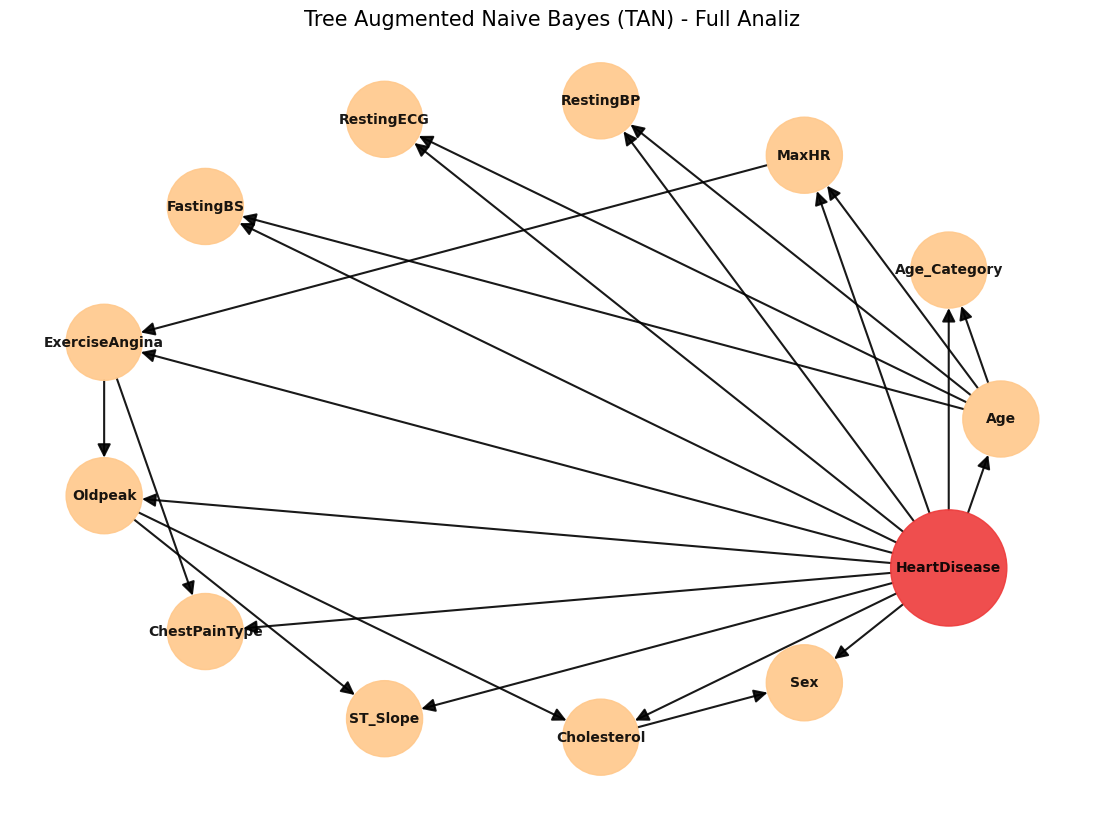

In [17]:
# ---------------------------------------------------------
# ADIM 6: GÖRSELLEŞTİRME
# ---------------------------------------------------------
print("\n--- 5. AĞ YAPISI ÇİZİLİYOR ---")
try:
    plt.figure(figsize=(14, 10))
    
    G = nx.DiGraph()
    G.add_edges_from(model.edges())
    
    all_nodes = list(G.nodes())
    
    # Görsellik ayarları
    node_colors = ['#EE3B3B' if node == target_col else '#FFC88B' for node in all_nodes]
    node_sizes = [7000 if node == target_col else 3000 for node in all_nodes]
    
    pos = nx.circular_layout(G)
    
    nx.draw_networkx(G, pos, with_labels=True, node_color=node_colors, node_size=node_sizes, 
                     font_size=10, font_weight="bold", arrowsize=20, width=1.5, alpha=0.9)
    
    plt.title("Tree Augmented Naive Bayes (TAN) - Full Analiz", fontsize=15)
    plt.axis('off')
    
    plt.savefig('HeartDisease_TAN_Network.pdf', format='pdf', bbox_inches='tight')
    print("Grafik 'HeartDisease_TAN_Network.pdf' olarak kaydedildi.")
    plt.show()
except Exception as e:
    print(f"Görselleştirme Hatası: {e}")